In [20]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [21]:

df = pd.read_csv("titanic.csv")

print(df.head())
print(df.shape)
print(df.isnull().sum())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  
(8

In [22]:

import pandas as pd

df = df.drop(columns=['Name', 'Ticket', 'Cabin'])

# Fill missing values
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

# Convert categorical columns into numerical columns
df = pd.get_dummies(
    df,
    columns=['Sex', 'Embarked', 'Pclass'],
    drop_first=True,
    dtype=int
)

# Shuffle the rows
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

# Display results
print(df.head())
print(df.shape)
print(df.isnull().sum())

   PassengerId  Survived   Age  SibSp  Parch     Fare  Sex_male  Embarked_Q  \
0          710         1  28.0      1      1  15.2458         1           0   
1          440         0  31.0      0      0  10.5000         1           0   
2          841         0  20.0      0      0   7.9250         1           0   
3          721         1   6.0      0      1  33.0000         0           0   
4           40         1  14.0      1      0  11.2417         0           0   

   Embarked_S  Pclass_2  Pclass_3  
0           0         0         1  
1           1         1         0  
2           1         0         1  
3           1         1         0  
4           0         0         1  
(891, 11)
PassengerId    0
Survived       0
Age            0
SibSp          0
Parch          0
Fare           0
Sex_male       0
Embarked_Q     0
Embarked_S     0
Pclass_2       0
Pclass_3       0
dtype: int64


In [23]:
x = df.drop('Survived', axis=1)
y = df['Survived'].values

m = len(x)
split = int(0.8 * m)

x_train = x[:split]
x_test = x[split:]

y_train = y[:split]
y_test = y[split:]

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)


Training data: (712, 10)
Testing data: (179, 10)


In [24]:
x_mean = np.mean(x_train, axis=0)
x_std = np.std(x_train, axis=0)

x_std[x_std == 0] = 1

x_train = (x_train - x_mean) / x_std
x_test = (x_test - x_mean) / x_std

In [25]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

def compute_cost(x, y, w, b, lambda_reg=0):
    m = len(y)

    z = np.dot(x, w) + b
    f = sigmoid(z)

    f = np.clip(f, 1e-10, 1 - 1e-10)

    cost = -np.mean(
        y * np.log(f) + (1 - y) * np.log(1 - f)
    )

    reg_cost = lambda_reg * np.sum(w ** 2) / (2 * m)

    return cost + reg_cost

def gradient_descent(
    x, y, x_test, y_test, w, b,
    alpha, iterations, lambda_reg=0
):
    m = len(y)

    train_cost_history = []
    test_cost_history = []

    for i in range(iterations):
        z = np.dot(x, w) + b
        f = sigmoid(z)

        error = f - y

        dj_dw = np.dot(x.T, error) / m
        dj_db = np.sum(error) / m

        dj_dw = dj_dw + (lambda_reg / m) * w

        w = w - alpha * dj_dw
        b = b - alpha * dj_db

        train_cost_history.append(
            compute_cost(x_train, y_train, w, b, lambda_reg)
        )

        test_cost_history.append(
            compute_cost(x_test, y_test, w, b, lambda_reg)
        )

    return w, b, train_cost_history, test_cost_history

In [26]:
n = x_train.shape[1]

w = np.zeros(n)
b = 0

alpha = 0.01
iterations = 1000

w, b, train_cost_history, test_cost_history = gradient_descent(
    x_train,
    y_train,
    x_test,
    y_test,
    w,
    b,
    alpha,
    iterations
)

print("Training complete")

Training complete


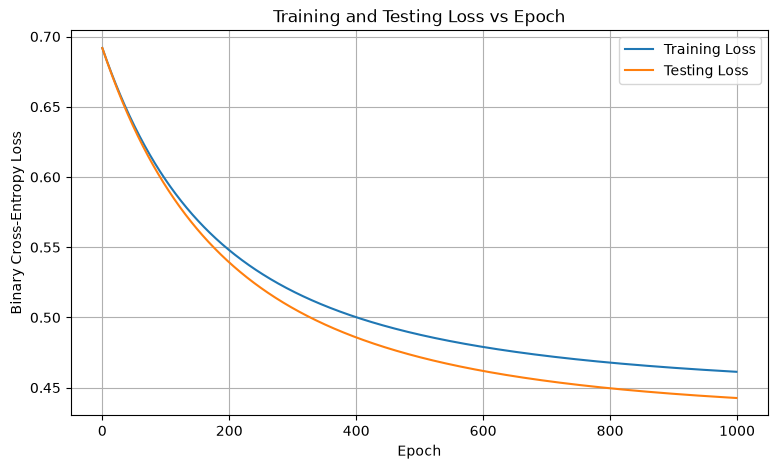

In [27]:
plt.figure(figsize=(9, 5))

plt.plot(train_cost_history, label="Training Loss")
plt.plot(test_cost_history, label="Testing Loss")

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Training and Testing Loss vs Epoch")

plt.legend()
plt.grid()
plt.show()

In [28]:
train_probabilities = sigmoid(np.dot(x_train, w) + b)
test_probabilities = sigmoid(np.dot(x_test, w) + b)

train_predictions = (train_probabilities >= 0.5).astype(int)
test_predictions = (test_probabilities >= 0.5).astype(int)

print("Actual survival:", y_test[:10])
print("Predicted survival:", test_predictions[:10])
print("Predicted probabilities:", test_probabilities[:10])

Actual survival: [0 0 1 1 1 0 1 1 0 0]
Predicted survival: [0 0 0 1 1 0 1 0 0 0]
Predicted probabilities: [0.32337391 0.11571395 0.37818211 0.71157359 0.78354268 0.1226416
 0.76188493 0.4194133  0.32181383 0.41902694]


In [29]:
def evaluate_model(y_actual, predictions, probabilities):
    accuracy = np.mean(y_actual == predictions)

    tp = np.sum((y_actual == 1) & (predictions == 1))
    fp = np.sum((y_actual == 0) & (predictions == 1))
    fn = np.sum((y_actual == 1) & (predictions == 0))

    precision = tp / (tp + fp) if tp + fp > 0 else 0
    recall = tp / (tp + fn) if tp + fn > 0 else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0
    )

    probabilities = np.clip(
        probabilities, 1e-10, 1 - 1e-10
    )

    log_loss = -np.mean(
        y_actual * np.log(probabilities)
        + (1 - y_actual) * np.log(1 - probabilities)
    )

    return accuracy, precision, recall, f1, log_loss


train_metrics = evaluate_model(
    y_train, train_predictions, train_probabilities
)

test_metrics = evaluate_model(
    y_test, test_predictions, test_probabilities
)

metrics = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score', 'Log Loss'],
    'Training': train_metrics,
    'Testing': test_metrics
})

print(metrics)

      Metric  Training   Testing
0   Accuracy  0.796348  0.821229
1  Precision  0.761905  0.770492
2     Recall  0.693141  0.723077
3   F1-score  0.725898  0.746032
4   Log Loss  0.461319  0.442666


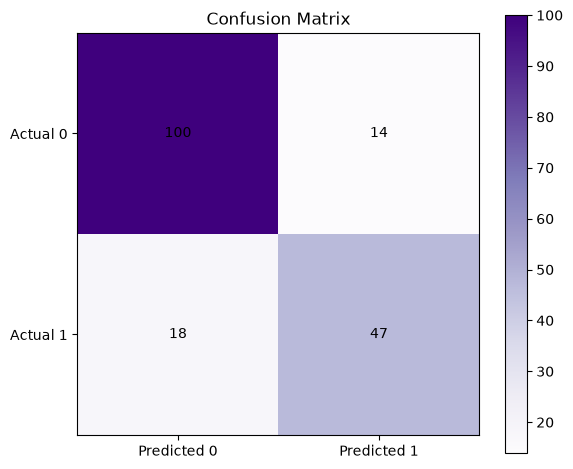

In [30]:
tn = np.sum((y_test == 0) & (test_predictions == 0))
fp = np.sum((y_test == 0) & (test_predictions == 1))
fn = np.sum((y_test == 1) & (test_predictions == 0))
tp = np.sum((y_test == 1) & (test_predictions == 1))

confusion = np.array([
    [tn, fp],
    [fn, tp]
])

plt.figure(figsize=(6, 5))
plt.imshow(confusion, cmap='Purples')
plt.colorbar()

plt.xticks([0, 1], ['Predicted 0', 'Predicted 1'])
plt.yticks([0, 1], ['Actual 0', 'Actual 1'])

for i in range(2):
    for j in range(2):
        plt.text(j, i, confusion[i, j],
                 ha='center', va='center')

plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

In [31]:
alphas = [0.001, 0.01, 0.04]
iteration_values = [750, 1000, 2000]

tuning_results = []

for alpha_value in alphas:
    for iteration_value in iteration_values:

        w_temp = np.zeros(x_train.shape[1])
        b_temp = 0

        w_temp, b_temp, train_history, test_history = gradient_descent(
            x_train, y_train,
            x_test, y_test,
            w_temp, b_temp,
            alpha_value, iteration_value
        )

        probabilities = sigmoid(np.dot(x_test, w_temp) + b_temp)

        predictions = (probabilities >= 0.5).astype(int)

        test_log_loss = evaluate_model(
            y_test, predictions, probabilities
        )[4]

        tuning_results.append([
            alpha_value, iteration_value, test_log_loss
        ])

tuning_df = pd.DataFrame(
    tuning_results,
    columns=['Alpha', 'Iterations', 'Test Log Loss']
)

print(tuning_df)

best_index = tuning_df['Test Log Loss'].idxmin()
best_result = tuning_df.loc[best_index]

print("\nBest Alpha:", best_result['Alpha'])
print("Best Iterations:", best_result['Iterations'])
print("Test Log Loss:", best_result['Test Log Loss'])

   Alpha  Iterations  Test Log Loss
0  0.001         750       0.613455
1  0.001        1000       0.594222
2  0.001        2000       0.539691
3  0.010         750       0.452055
4  0.010        1000       0.442666
5  0.010        2000       0.432708
6  0.040         750       0.431908
7  0.040        1000       0.432209
8  0.040        2000       0.433337

Best Alpha: 0.04
Best Iterations: 750.0
Test Log Loss: 0.4319080724594726


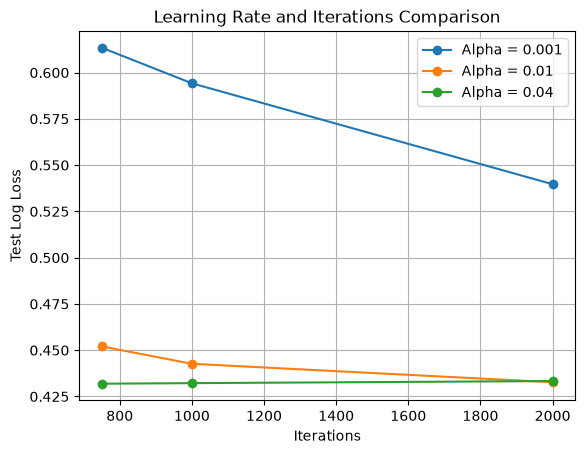

In [32]:
for alpha_value in alphas:
    selected = tuning_df[tuning_df['Alpha'] == alpha_value]

    plt.plot(
        selected['Iterations'],
        selected['Test Log Loss'],
        marker='o',
        label='Alpha = ' + str(alpha_value)
    )

plt.xlabel("Iterations")
plt.ylabel("Test Log Loss")
plt.title("Learning Rate and Iterations Comparison")

plt.legend()
plt.grid()
plt.show()

In [33]:
lambda_values = [0, 0.01, 0.1, 1, 10]
reg_results = []

for lambda_value in lambda_values:
    w_temp = np.zeros(x_train.shape[1])
    b_temp = 0

    w_temp, b_temp, train_history, test_history = gradient_descent(
        x_train, y_train,
        x_test, y_test,
        w_temp, b_temp,
        float(best_result['Alpha']),
        int(best_result['Iterations']),
        lambda_value
    )

    probabilities = sigmoid(np.dot(x_test, w_temp) + b_temp)
    predictions = (probabilities >= 0.5).astype(int)

    test_log_loss = evaluate_model(
        y_test, predictions, probabilities
    )[4]

    reg_results.append([lambda_value, test_log_loss])

reg_df = pd.DataFrame(
    reg_results,
    columns=['Lambda', 'Test Log Loss']
)

print(reg_df)

   Lambda  Test Log Loss
0    0.00       0.431908
1    0.01       0.431910
2    0.10       0.431926
3    1.00       0.432099
4   10.00       0.434743


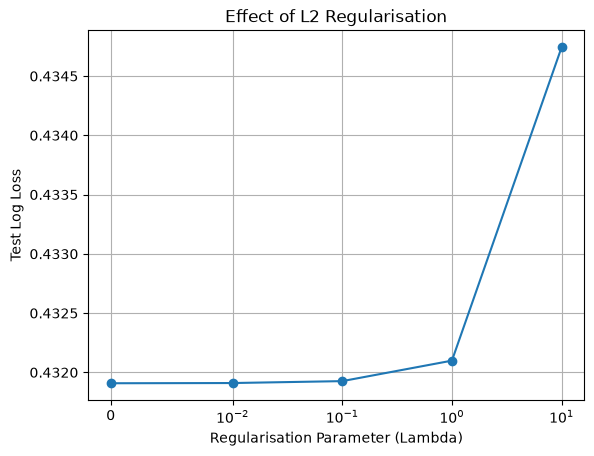

In [34]:
plt.plot(
    reg_df['Lambda'],
    reg_df['Test Log Loss'],
    marker='o'
)

plt.xlabel("Regularisation Parameter (Lambda)")
plt.ylabel("Test Log Loss")
plt.title("Effect of L2 Regularisation")

plt.xscale("symlog", linthresh=0.01)
plt.grid()
plt.show()

In [35]:
best_reg_index = reg_df['Test Log Loss'].idxmin()
best_lambda = reg_df.loc[best_reg_index, 'Lambda']

w_final = np.zeros(x_train.shape[1])
b_final = 0

w_final, b_final, train_history, test_history = gradient_descent(
    x_train, y_train,
    x_test, y_test,
    w_final, b_final,
    float(best_result['Alpha']),
    int(best_result['Iterations']),
    float(best_lambda)
)

train_probabilities = sigmoid(np.dot(x_train, w_final) + b_final)
test_probabilities = sigmoid(np.dot(x_test, w_final) + b_final)

train_predictions = (train_probabilities >= 0.5).astype(int)
test_predictions = (test_probabilities >= 0.5).astype(int)

print("----- Final Results -----")
print("Alpha:", best_result['Alpha'])
print("Iterations:", best_result['Iterations'])
print("Lambda:", best_lambda)

print("\nTraining Metrics:")
print(evaluate_model(y_train, train_predictions, train_probabilities))

print("\nTesting Metrics:")
print(evaluate_model(y_test, test_predictions, test_probabilities))

----- Final Results -----
Alpha: 0.04
Iterations: 750.0
Lambda: 0.0

Training Metrics:
(np.float64(0.797752808988764), np.float64(0.7692307692307693), np.float64(0.6859205776173285), np.float64(0.7251908396946566), np.float64(0.4469010275196343))

Testing Metrics:
(np.float64(0.7988826815642458), np.float64(0.7301587301587301), np.float64(0.7076923076923077), np.float64(0.7187500000000001), np.float64(0.4319080724594726))
